
# Cluster Buster Multimodal Image Processing and Bangla Text Quality Analysis


## Overview

This project focuses on exploring and preprocessing the BanglaCalamityMMD dataset, which contains images and Bangla text related to disaster identification. The main goal is to understand the dataset, perform basic image processing, examine the quality of Bangla text, and check whether the text and images are correctly matched.

## Objectives

- Load and explore the dataset and its CSV files.
- Perform basic image processing and visualization.
- Examine image pixels, RGB channels, and image transformations.
- Check Bangla text for missing values, empty entries, and duplicates.
- Analyze text length and disaster label distribution.
- Check image–text alignment and identify unmatched records.
- Prepare the dataset for future multimodal machine learning experiments.

## Tools and Libraries

- Python
- Jupyter Notebook
- Pandas and NumPy
- OpenCV
- Matplotlib


## Import libraries and set the dataset path

Install missing packages in a separate notebook cell if needed:
`%pip install pandas numpy matplotlib opencv-python`

In [94]:
from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 180)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams['font.family'] = 'Nirmala UI'

## Set the dataset path and file locations

This cell defines where the dataset is stored on the computer. Nothing is loaded or changed here. It only sets up the addresses that the rest of the notebook uses.

`DATASET_PATH` points to the main folder that holds everything, and it is the only line that needs editing if the dataset is saved somewhere else. `CSV_PATHS` points to the train, validation and test CSV files, which contain the image IDs, Bangla text and categories. `IMAGE_DIRS` points to the folders with the actual images for each split. `IMAGE_EXTENSIONS` lists the file types treated as images (such as `.jpg` and `.png`), so any other files in those folders are ignored.

At the end, the cell checks whether the dataset folder exists and prints its contents. If everything is correct, the output shows `Dataset folder exists: True` along with the three CSV files and the train, validation and test folders. If it shows `False`, the path is wrong, or it points to a ZIP file instead of the extracted folder.

In [95]:
DATASET_PATH = Path(r"D:\STUDY MATERIALS\7th semester\CSE-4878 Machine Learning and Data Mining Lab\BanglaCalamityMMD")

CSV_PATHS = {
    "train": DATASET_PATH / "Disaster_train.csv",
    "validation": DATASET_PATH / "Disaster_validation.csv",
    "test": DATASET_PATH / "Disaster_test.csv",
}
IMAGE_DIRS = {
    "train": DATASET_PATH / "train",
    "validation": DATASET_PATH / "validation",
    "test": DATASET_PATH / "test",
}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

print("Dataset folder exists:", DATASET_PATH.exists())
if DATASET_PATH.exists():
    print("Items in dataset folder:")
    for item in sorted(DATASET_PATH.iterdir()):
        print(" -", item.name)
else:
    print("Update DATASET_PATH. It should point to the extracted dataset folder, not the ZIP file.")

Dataset folder exists: True
Items in dataset folder:
 - Disaster_test.csv
 - Disaster_train.csv
 - Disaster_validation.csv
 - preprocessed_examples
 - quality_alignment_output
 - standardized_text_output
 - Test
 - Train
 - Validation


## Load the CSV files and inspect their structure

This cell reads the train, validation and test CSV files into memory and gives a quick first look at each one. The original files are not modified.

Each CSV is loaded into a pandas table and stored in a dictionary called `dataframes`, with the split name (train, validation or test) as the key. If a file is missing, a warning is printed and that split is skipped instead of crashing the notebook. The files are read as UTF-8 so Bangla text loads correctly, and if that fails, the UTF-8 with BOM version is tried as a fallback. If none of the files can be found, an error is raised, since the rest of the notebook depends on this data.

After loading, the cell prints a short summary for each split: the shape (number of rows and columns), the column names, and the first three rows. This makes it easy to confirm that the files loaded properly and to see what each column contains.

For this dataset, each split should show three columns: `image_id`, `context` (the Bangla text) and `category` (the disaster label). Row counts should be 6,323 for train and 790 each for validation and test. If the Bangla text appears as strange symbols, the file encoding is the first thing to check.

In [96]:
dataframes = {}
for split, csv_path in CSV_PATHS.items():
    if not csv_path.exists():
        print(f"Warning: {split} CSV not found: {csv_path}")
        continue
    try:
        dataframes[split] = pd.read_csv(csv_path, encoding="utf-8")
    except UnicodeDecodeError:
        dataframes[split] = pd.read_csv(csv_path, encoding="utf-8-sig")

if not dataframes:
    raise FileNotFoundError(
        "No CSV files were loaded. Check DATASET_PATH and the CSV filenames."
    )

for split, frame in dataframes.items():
    print(f"\n--- {split.upper()} ---")
    print("Shape (rows, columns):", frame.shape)
    print("Columns:", frame.columns.tolist())
    display(frame.head(3))


--- TRAIN ---
Shape (rows, columns): (6323, 3)
Columns: ['image_id', 'context', 'category']


,image_id,context,category
0,landslides_1,"ভারী বৃষ্টিপাতের কারণে ভূমিধসের সূত্রপাত হয়েছে যা ঘরবাড়ি ধ্বংস করেছে এবং দক্ষিণ ইতালীয় দ্বীপ ইসচিয়াতে অন্তত সাতজন নিহত হয়েছে, যার মধ্যে দুই ভাইবোন, ৫ এবং ১১ এবং একটি নবজাত...",Landslides
1,landslides_2,"প্রবল বৃষ্টির মধ্যে ইতালির ইসচিয়া দ্বীপে একটি মারাত্মক ভূমিধস আঘাত হানে, একজনের মৃত্যু হয়েছে, ১০ জন এখনও নিখোঁজ রয়েছে।",Landslides
2,landslides_3,সোমবার একটি পাহাড়ের পাশে একটি বিশাল ভূমিধসের কারণে দক্ষিণ ইতালির একটি শহরের প্রায় ২০০ বাসিন্দাকে সরিয়ে নেওয়া হয়েছে।,Landslides



--- VALIDATION ---
Shape (rows, columns): (790, 3)
Columns: ['image_id', 'context', 'category']


,image_id,context,category
0,landslides_904,"ঝড়ের তোড়ে লিগুরিয়া: ভূমিসৃতি ও বন্যা, ১০ জন নিখোঁজ, ক্ষতির পরিমাণ কোটি টাকা! উত্তর ইতালির লিগুরিয়া অঞ্চলে সোমবার শক্তিশালী ঝড়ের কবলে পড়েছে। দুর্যোগে ঘন্টার পর ঘন্টা অবিরা...",Landslides
1,landslides_905,"পাহাড় ধসে নিহত ৫, আহত কমপক্ষে ২০ জন ইতালির উত্তর-পশ্চিমাঞ্চলীয় অঞ্চলে একটি যাত্রীবাহী ট্রেন পাহাড় ধসের নিচে আটকে পড়ে। ট্রেনটি দ্রুত গতিতে চলায় ফলে দুর্ঘটনাটি আরও ভয়াবহ হয...",Landslides
2,landslides_906,রাতের ভূমিধস: তুষারে আটকেপড়েছে ১০০ পর্যটক! ইতালির আল্পস পর্বতমালার একটি স্কাই রিসোর্টে রাতের অंधকারে ভয়াবহ ভূমিসৃতি ঘটেছে। এতে প্রায় ১০০ পর্যটক তুষারে আটকে পড়েছে। উদ্ধারকর্...,Landslides



--- TEST ---
Shape (rows, columns): (790, 3)
Columns: ['image_id', 'context', 'category']


,image_id,context,category
0,landslides_804,গত মাসে ইতালির ইস্কিয়া দ্বীপে ভূমিধসে নিখোঁজ থাকা শেষ ব্যক্তির মৃতদেহ উদ্ধার করেছেন উদ্ধারকর্মীরা। ফলে চূড়ান্ত মৃত্যুর সংখ্যা বেড়ে দাঁড়িয়েছে ১২ জনে। অবিরাম বৃষ্টিপাতের পর ...,Landslides
1,landslides_805,"ইতালির সিসিলি দ্বীপে প্রচণ্ড বর্ষণের পর ভূমিধস: একাধিক বাড়ি মাটির নিচে চাপা পড়েছে, জরুরি সেবা সক্রিয় উদ্ধার অভিযানে নেমেছে এবং আহত ব্যক্তিদের জন্য চিকিৎসা টিম মোতায়েন করা হ...",Landslides
2,landslides_806,"ভেনিসের কাছাকাছি এলাকায় ভূমিধসের ফলে বহু বাড়ি ঝুঁকিপূর্ণ হয়ে পড়েছে, যার ফলে কর্তৃপক্ষ জরুরি ভিত্তিতে নিরাপদ আশ্রয়ে স্থানান্তরের জন্য আহ্বান জানিয়েছে। উদ্ধার ও সহায়তা কার...",Landslides


## Identify the text, image and label columns

This cell figures out which column in the CSV holds the Bangla text, which holds the image names, and which holds the category labels. The rest of the notebook uses these three names, so they need to be correct.

It looks at the column names in the training data and guesses each one by searching for common keywords. For example, a column with a name like "text" or "content" is treated as the text column, "image" or "file" as the image column, and "label" or "category" as the label column. The three guesses are saved as `TEXT_COLUMN`, `IMAGE_COLUMN` and `LABEL_COLUMN`, then printed along with the full list of available columns.

For this dataset, the output should show `context` as the text column, `image_id` as the image column, and `category` as the label column. If any guess is wrong or shows `None`, set the correct column name manually before moving on.

In [121]:
train_df = dataframes.get("train", next(iter(dataframes.values())))

def suggest_column(columns, keywords):
    for col in columns:
        if any(word in str(col).lower() for word in keywords):
            return col
    return None

columns = list(train_df.columns)
TEXT_COLUMN = suggest_column(columns, ["text", "caption", "tweet", "post", "content", "description", "bangla"])
IMAGE_COLUMN = suggest_column(columns, ["image_id", "img", "photo", "filename", "file", "path", "media"])
LABEL_COLUMN = suggest_column(columns, ["label", "class", "category", "target"])

print("Available columns:", columns)
print("Suggested TEXT_COLUMN:", TEXT_COLUMN)
print("Suggested IMAGE_COLUMN:", IMAGE_COLUMN)
print("Suggested LABEL_COLUMN:", LABEL_COLUMN)

Available columns: ['image_id', 'context', 'category', 'standardized_text', 'matched_image_path']
Suggested TEXT_COLUMN: context
Suggested IMAGE_COLUMN: image_id
Suggested LABEL_COLUMN: category


## Count the images and load a sample image

This cell counts how many images are in each split folder and then loads one training image to use for the image-processing demonstrations that follow. The original image files are not changed.

First, it goes through the train, validation and test folders (including any subfolders) and counts the files with valid image extensions. If a folder is missing, a message is printed instead. Next, it collects all the training images into a sorted list and tries to open them one by one until it finds the first image that can be read properly. That image is saved as the sample for the next sections.

OpenCV loads images in BGR color order, while Matplotlib expects RGB, so the image is converted to RGB before display. The cell then prints the file path and the image shape (height, width and number of color channels) and shows the image on screen.

For this dataset, the counts should be 6,323 train, 790 validation and 790 test images, matching the row counts in the CSV files. If no readable image is found, check the train folder path and the image formats.

train: 6323 images
validation: 790 images
test: 790 images
Training images found: 6323
Selected image: D:\STUDY MATERIALS\7th semester\CSE-4878 Machine Learning and Data Mining Lab\BanglaCalamityMMD\train\drought_1.jpg
Image shape (height, width, channels): (1334, 2000, 3)


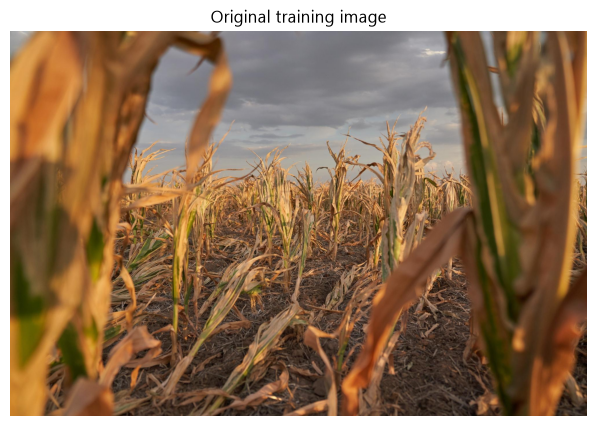

In [98]:
for split, folder in IMAGE_DIRS.items():
    if folder.exists():
        count = sum(1 for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        print(f"{split}: {count} images")
    else:
        print(f"{split}: image folder not found ({folder})")

TRAIN_PATH = IMAGE_DIRS.get("train")
image_files = (
    sorted(p for p in TRAIN_PATH.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    if TRAIN_PATH and TRAIN_PATH.exists() else []
)
print("Training images found:", len(image_files))

image_path, image, image_rgb = None, None, None
for candidate in image_files:
    loaded = cv2.imread(str(candidate))
    if loaded is not None:
        image_path, image = candidate, loaded
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        break

if image is None:
    print("No readable training image found. Check the train folder and image formats.")
else:
    print("Selected image:", image_path)
    print("Image shape (height, width, channels):", image.shape)
    plt.imshow(image_rgb)
    plt.title("Original training image")
    plt.axis("off")
    plt.show()

## Look at the pixel values of the image

This cell shows what an image looks like to the computer. A picture is stored as a grid of numbers, and this cell prints a small piece of that grid so the idea becomes concrete.

It first prints the shape of the image array, which is the height, the width and the number of color channels. Then it prints the pixel values from the top-left corner, covering the first 5 rows and 5 columns. Each pixel holds three numbers between 0 and 255, one for each color channel. Because OpenCV loads images in BGR order, the numbers are listed as blue, green and red. Low values mean dark and high values mean bright.

In the output, the three numbers in each pixel are equal (for example 155, 155, 155), which means that part of the image is a shade of gray. Neighboring pixels also have similar values, which is normal because nearby areas in a photo usually look alike.

In [99]:
if image is not None:
    print("Image array shape:", image.shape)
    print("Small section of BGR pixel values:")
    print(image[:5, :5])

Image array shape: (1334, 2000, 3)
Small section of BGR pixel values:
[[[155 155 155]
  [155 155 155]
  [156 156 156]
  [157 157 157]
  [158 158 158]]

 [[157 157 157]
  [157 157 157]
  [158 158 158]
  [159 159 159]
  [160 160 160]]

 [[158 158 158]
  [159 159 159]
  [160 160 160]
  [161 161 161]
  [162 162 162]]

 [[158 158 158]
  [159 159 159]
  [160 160 160]
  [161 161 161]
  [163 163 163]]

 [[156 156 156]
  [157 157 157]
  [158 158 158]
  [160 160 160]
  [161 161 161]]]


## Split the image into red, green and blue channels

This cell separates the image into its three color channels so each one can be seen on its own. A color image is built from red, green and blue layers stacked together, and this shows what each layer contributes.

It makes three copies of the RGB image. In each copy, two channels are set to zero, so only one color remains: red keeps only the red layer, green keeps only the green layer, and blue keeps only the blue layer. The original image is not changed. The four images are then displayed side by side: the original, the red channel, the green channel and the blue channel.

Areas that look bright in a channel contain a lot of that color, and dark areas contain little of it. This is useful for understanding which colors dominate an image. For disaster images, that can hint at things like orange tones in fires or brown tones in floodwater.

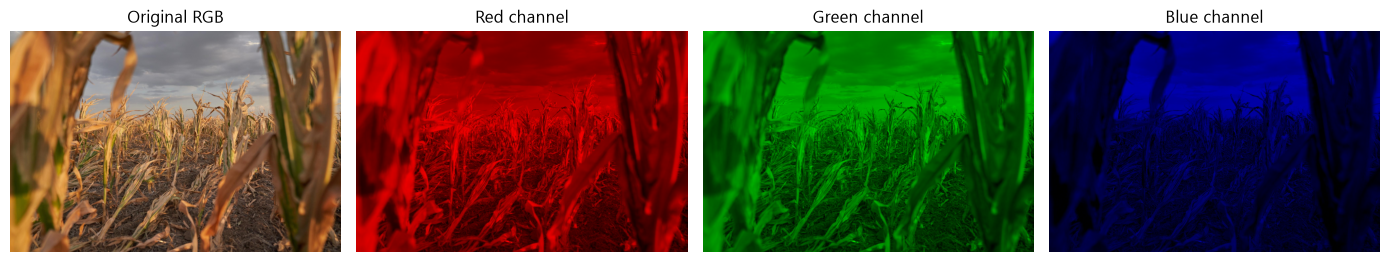

In [100]:
if image_rgb is not None:
    red, green, blue = image_rgb.copy(), image_rgb.copy(), image_rgb.copy()
    red[:, :, 1:] = 0
    green[:, :, [0, 2]] = 0
    blue[:, :, :2] = 0

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    for ax, arr, title in zip(axes, [image_rgb, red, green, blue],
                              ["Original RGB", "Red channel", "Green channel", "Blue channel"]):
        ax.imshow(arr); ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

## Edit pixels directly by adding a blue square

This cell shows that an image can be edited by changing its pixel values. It draws a small blue square on a copy of the image, which makes the idea of an image being just an array of numbers easy to see.

It first makes a copy of the RGB image, so the original image in memory and the file on disk stay unchanged. Then it selects a block of pixels near the top-left corner, from row 20 to 70 and column 20 to 70, and sets all of them to the value `[0, 0, 255]`. In RGB order, that means no red, no green and full blue. The `min()` checks keep the square inside the image even if the image is very small. The edited copy is then displayed.

The output should be the same image with a solid blue square in the top-left corner. This is only a demonstration of how pixel editing works and is not part of the actual preprocessing.## 6. Basic image-processing demonstrations

These operations are demonstrations for learning and inspection. They do not modify the original image file.

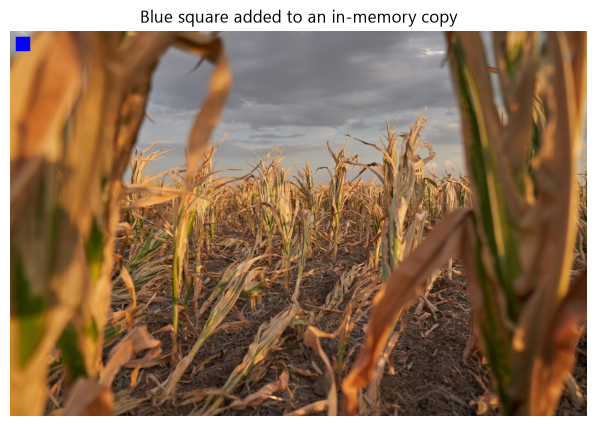

In [124]:
if image_rgb is not None:
    edited_image = image_rgb.copy()
    h, w = edited_image.shape[:2]
    edited_image[min(20, h):min(70, h), min(20, w):min(70, w)] = [0, 0, 255]
    plt.imshow(edited_image)
    plt.title("Blue square added to an in-memory copy")
    plt.axis("off"); plt.show()

## Convert the image to grayscale

This cell converts the color image into a grayscale (black and white) version. Grayscale removes color information and keeps only brightness, which makes the image simpler to work with.

A color image has three values per pixel (blue, green and red), while a grayscale image has just one value per pixel, from 0 (black) to 255 (white). The conversion combines the three color channels into a single brightness value. The result is stored in `gray_image`, which is also used by the next sections for thresholding and edge detection. The original color image is not changed.

The output should be the same picture in shades of gray. Grayscale is useful for simple image-processing tasks, but it is not recommended for disaster classification, since color carries important clues such as orange flames or brown floodwater.

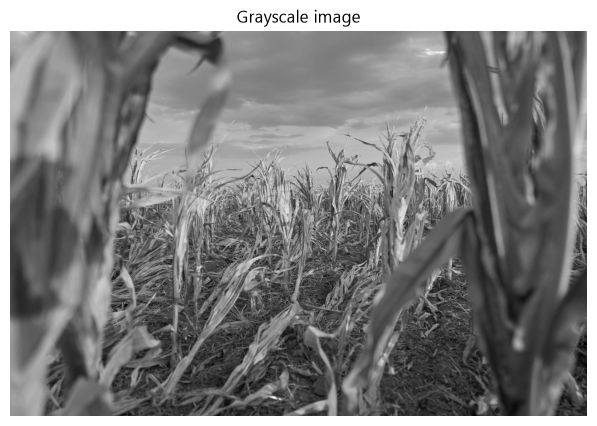

In [102]:
if image is not None:
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    plt.imshow(gray_image, cmap="gray")
    plt.title("Grayscale image")
    plt.axis("off"); plt.show()

## Convert the grayscale image to a binary image

This cell turns the grayscale image into a pure black and white image using a method called thresholding. It shows how an image can be simplified to just two values.

Thresholding compares every pixel with a cutoff value, here 127. Pixels brighter than 127 become white (255), and all other pixels become black (0). The result is stored in `binary_image`. The cell then displays the grayscale image and the binary image side by side so the difference is easy to see. The original image is not changed.

The binary version keeps only the rough shapes and the light and dark regions, and all the fine detail is lost. This is useful for tasks like separating an object from its background, but it is not recommended for disaster classification, since too much useful information is removed.

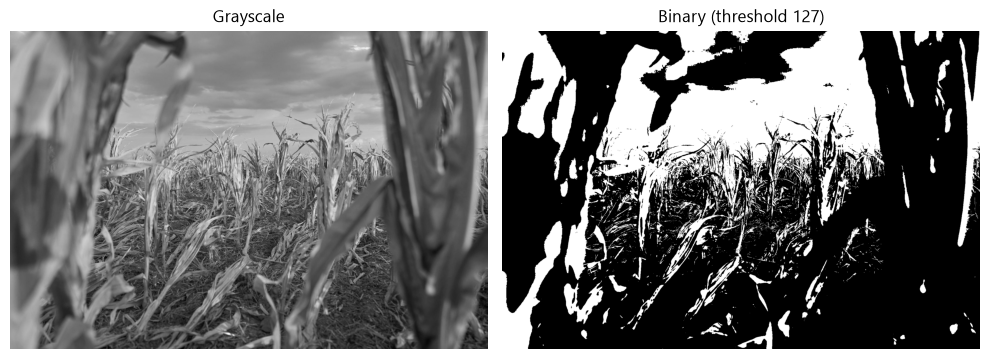

In [103]:
if image is not None:
    _, binary_image = cv2.threshold(gray_image, 127, 255, cv2.THRESH_BINARY)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(gray_image, cmap="gray"); axes[0].set_title("Grayscale")
    axes[1].imshow(binary_image, cmap="gray"); axes[1].set_title("Binary (threshold 127)")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

## Resize the image to 224 × 224

This cell changes the image to a fixed size of 224 × 224 pixels. Most image models expect every input to have the same size, so resizing is one of the most common preprocessing steps.

The color image is shrunk to 224 pixels wide and 224 pixels tall using `cv2.resize`. The `INTER_AREA` option is a method that works well when making an image smaller, because it blends nearby pixels and keeps the result looking smooth. The resized image is stored in `resized_image`, which is also used in later sections, then displayed along with its new shape. The original image is not changed.

The printed shape should be `(224, 224, 3)`, which means 224 pixels high, 224 pixels wide and 3 color channels. The original image was not square, so the resized version looks slightly stretched or squeezed. Some pipelines avoid this by cropping or padding the image instead of resizing it directly.

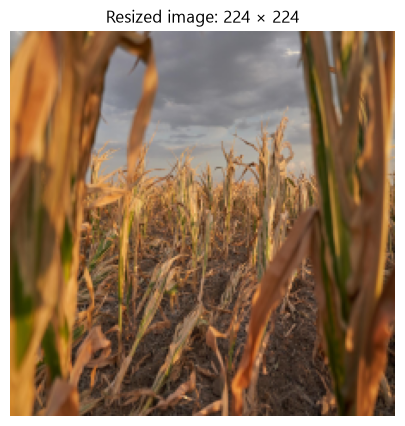

Resized shape: (224, 224, 3)


In [104]:
if image_rgb is not None:
    resized_image = cv2.resize(image_rgb, (224, 224), interpolation=cv2.INTER_AREA)
    plt.imshow(resized_image)
    plt.title("Resized image: 224 × 224")
    plt.axis("off"); plt.show()
    print("Resized shape:", resized_image.shape)

## Detect edges and compare the processing steps

This cell finds the edges in the image, meaning the lines where brightness changes sharply, such as the outline of a building, a tree line or the border of floodwater. It then displays the original, grayscale, resized and edge versions side by side so the effect of each step can be compared.

Edge detection works on the grayscale image. First, a light Gaussian blur (`GaussianBlur`) smooths out small noise, so tiny specks are not mistaken for edges. Then the Canny method (`cv2.Canny`) marks pixels where the brightness changes strongly. The two numbers, 100 and 200, are thresholds: changes above 200 are kept as strong edges, changes below 100 are ignored, and changes in between are kept only if they connect to strong edges. The result is a black image with white lines showing the shapes in the scene. The original image is not changed.

**Why this is important:** edges are one of the most basic ways a computer sees structure in an image. Before looking at objects, models first pick up on edges, textures and shapes, and these are built up into more complex features such as damaged buildings, collapsed walls or flooded streets. Seeing the edge map shows what information is kept when color is removed and how much of the scene is still recognizable from its outlines alone. It also helps explain why blur and noise matter, since they hide edges and make images harder to classify.

Canny edges are shown here for learning and are not part of the final preprocessing. Modern deep learning models learn their own edge and texture detectors from the color images, so the edge map is not fed to them directly.

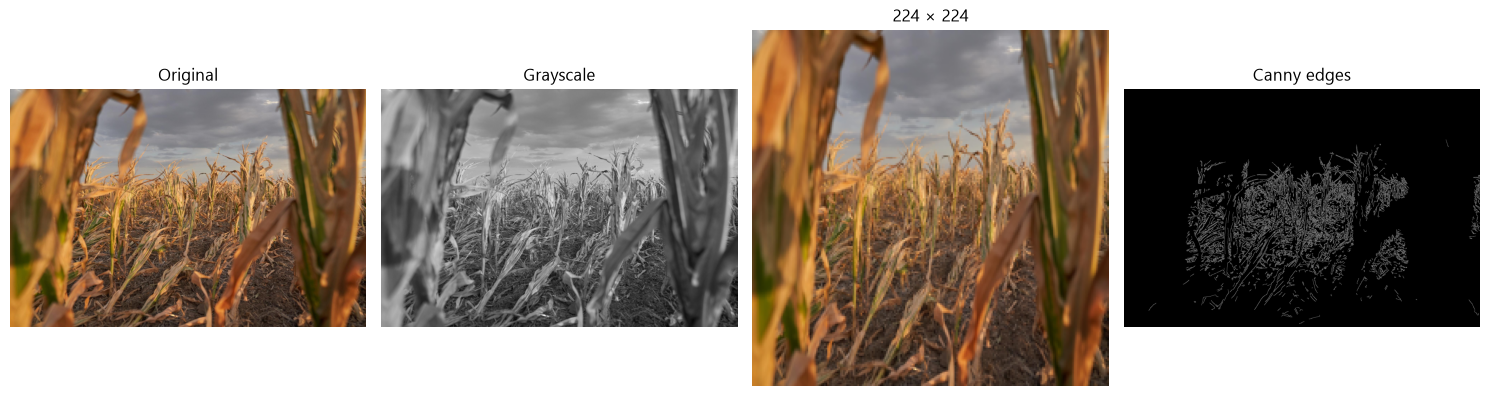

In [105]:
if image is not None:
    blurred_gray = cv2.GaussianBlur(gray_image, (3, 3), 0)
    edges = cv2.Canny(blurred_gray, 100, 200)
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    axes[0].imshow(image_rgb); axes[0].set_title("Original")
    axes[1].imshow(gray_image, cmap="gray"); axes[1].set_title("Grayscale")
    axes[2].imshow(resized_image); axes[2].set_title("224 × 224")
    axes[3].imshow(edges, cmap="gray"); axes[3].set_title("Canny edges")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

## Flip and rotate the image

This cell shows three simple geometric changes: a horizontal flip, a vertical flip and a 90° rotation. The original image and the three transformed versions are displayed side by side for comparison.

A horizontal flip mirrors the image left to right, and a vertical flip mirrors it top to bottom. The 90° rotation turns the image clockwise, so the width and height swap. All three are applied to copies, so the original image is not changed.

**Why this is important:** these operations are the basis of data augmentation. By showing a model flipped and rotated versions of the same image, a small dataset can be made to look larger and more varied, which helps the model learn the disaster itself and not the exact position or orientation of things in the picture. A horizontal flip is usually safe, since a flooded street or a burning building looks the same mirrored.

These transformations need care. A vertical flip or a 90° rotation makes most ground-level photos look unrealistic, because the sky ends up at the bottom or the side. They make more sense for satellite or aerial images, which have no fixed "up". They are shown here for learning and should not be applied automatically to every disaster image.

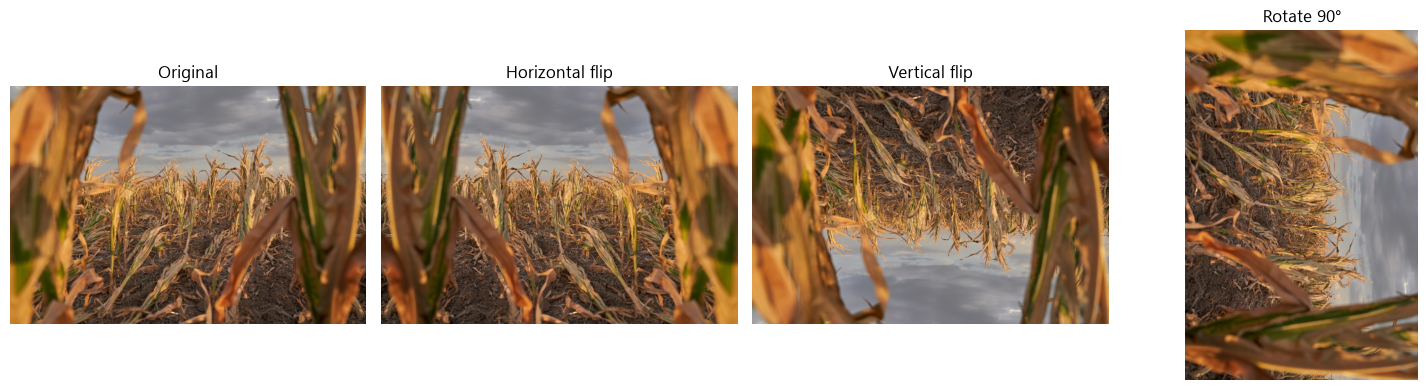

In [106]:
if image_rgb is not None:
    horizontal_flip = cv2.flip(image_rgb, 1)
    vertical_flip = cv2.flip(image_rgb, 0)
    rotated_image = cv2.rotate(image_rgb, cv2.ROTATE_90_CLOCKWISE)

    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    for ax, arr, title in zip(axes,
                              [image_rgb, horizontal_flip, vertical_flip, rotated_image],
                              ["Original", "Horizontal flip", "Vertical flip", "Rotate 90°"]):
        ax.imshow(arr); ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

## Change brightness, blur and sharpness

This cell shows four more image changes: making the image brighter, making it darker, blurring it strongly and sharpening it. The original and the four versions are displayed side by side so the differences are easy to compare.

Brightness is changed by adding or subtracting 35 from every pixel value (`beta=35` for brighter, `beta=-35` for darker), and the values are kept within the valid 0 to 255 range. The strong blur uses a large Gaussian filter, which smooths the image and hides fine detail. Sharpening works by blurring a copy of the image and then subtracting that blur from the original with extra weight (`addWeighted`), which makes edges and small details stand out more. The original image is not changed.

**Why this is important:** real disaster images come from many sources, such as phones, drones, news cameras and satellites, so they vary a lot in lighting and quality. Some are taken at night or in smoke, and some are blurry or low resolution. Training with brighter, darker and blurred versions can make a model more robust to these differences, and seeing the effects here helps in choosing realistic augmentation settings.

These changes should be used with care. Too much brightness change or blur can hide the very details that identify a disaster, such as flames, water level or damaged structures, and sharpening can add unnatural artifacts. They are shown here for learning and are not automatically applied to every image.

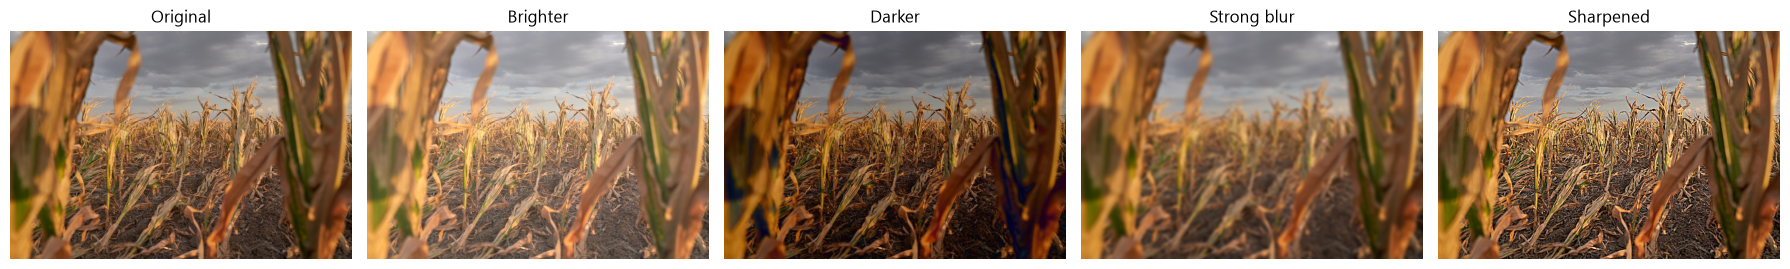

In [107]:
if image_rgb is not None:
    brighter_image = cv2.convertScaleAbs(image_rgb, alpha=1.0, beta=35)
    darker_image = cv2.convertScaleAbs(image_rgb, alpha=1.0, beta=-35)
    blurred_image = cv2.GaussianBlur(image_rgb, (31, 31), sigmaX=8)
    blur_for_sharpening = cv2.GaussianBlur(image_rgb, (0, 0), sigmaX=5)
    sharpened_image = cv2.addWeighted(image_rgb, 2.5, blur_for_sharpening, -1.5, 0)

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    for ax, arr, title in zip(axes,
        [image_rgb, brighter_image, darker_image, blurred_image, sharpened_image],
        ["Original", "Brighter", "Darker", "Strong blur", "Sharpened"]):
        ax.imshow(arr); ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

## Standardize the pixel values

This cell rescales the pixel values of the image so they are centered around zero with a spread of one. This is called standardization, and it is a common step before feeding images into a model.

The image is first converted from whole numbers (0 to 255) to decimal numbers (`float32`). Then the average pixel value is subtracted from every pixel, and the result is divided by the standard deviation, which measures how spread out the values are. If the standard deviation were zero, a division by 1 is used instead to avoid an error. The cell prints the new shape, the mean and the standard deviation. The mean should be almost exactly 0 (a tiny number like `3e-08` is just rounding) and the standard deviation should be 1. The original image is not changed.

**Why this is important:** models train better and faster when their inputs are on a similar, small scale. Raw values from 0 to 255 can make training unstable, while standardized values keep the numbers balanced. It also reduces the effect of an image being overall very bright or very dark.

The picture displayed here is for visualization only. Standardized values include negative numbers and cannot be shown directly as an image, so they are scaled back into a displayable range, and the image looks like a slightly different version of the original. Also, this cell standardizes one image using its own statistics. In a real pipeline, all images should be normalized the same way, usually with the fixed mean and standard deviation that the chosen pretrained model expects (for ImageNet models: mean `[0.485, 0.456, 0.406]` and std `[0.229, 0.224, 0.225]`).

Shape: (1334, 2000, 3)
Mean after standardization: 3.123438219176933e-08
Standard deviation after standardization: 1.0


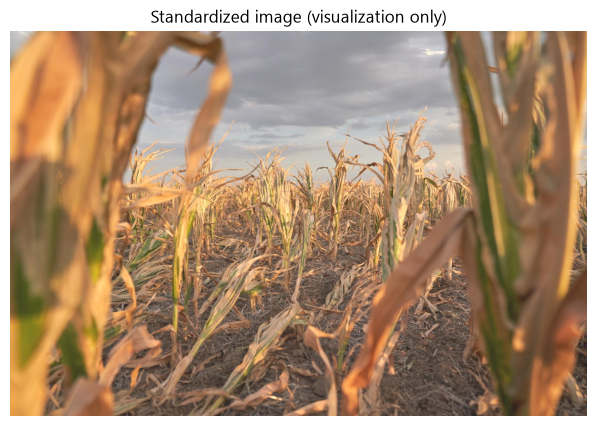

In [108]:
if image_rgb is not None:
    image_float = image_rgb.astype(np.float32)
    image_std = float(np.std(image_float))
    standardized_image = (image_float - np.mean(image_float)) / (image_std if image_std > 0 else 1.0)
    print("Shape:", standardized_image.shape)
    print("Mean after standardization:", float(np.mean(standardized_image)))
    print("Standard deviation after standardization:", float(np.std(standardized_image)))
    # Visualization only; not the actual normalized values.
    plt.imshow(np.clip(standardized_image * 0.2 + 0.5, 0, 1))
    plt.title("Standardized image (visualization only)")
    plt.axis("off"); plt.show()

## Clean the Bangla text

This cell cleans the Bangla text in a careful, minimal way and saves the result in a new column called `standardized_text`. The original text column is left untouched, so the raw and cleaned versions can be compared.

The cleaning is done by the function `standardize_bangla_text`, which applies three steps to each text. First, missing values are replaced with an empty string so later steps do not fail. Second, Unicode NFC normalization is applied, which makes sure characters that look identical are also stored identically. This matters in Bangla, where the same letter can sometimes be written with different underlying codes. Third, web links are removed and repeated spaces, tabs and line breaks are collapsed into a single space, with extra spaces trimmed from both ends. The function is then applied to every split that contains the text column, and the first 10 rows are displayed as original and cleaned side by side.

**Why this is important:** text that looks the same to a reader can differ at the character level, and models treat those differences as different words. Without normalization, the same word may be counted as two separate tokens, which weakens learning and can hide duplicates. Removing links and extra spacing also removes noise that carries no meaning for disaster classification.

The cleaning is deliberately light. Bangla letters, digits and punctuation such as the danda `।` are preserved, because removing too much could delete meaningful information. Because the changes are small, the original and cleaned text will usually look almost identical in the output, and that is expected.

In [109]:
def standardize_bangla_text(value):
    if pd.isna(value):
        return ""
    text = unicodedata.normalize("NFC", str(value))
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

if TEXT_COLUMN is not None:
    for split, frame in dataframes.items():
        if TEXT_COLUMN not in frame.columns:
            print(f"Warning: {TEXT_COLUMN!r} is not present in {split}; skipping text cleaning there.")
            continue
        frame["standardized_text"] = frame[TEXT_COLUMN].apply(standardize_bangla_text)
    if "standardized_text" in train_df.columns:
        display(train_df[[TEXT_COLUMN, "standardized_text"]].head(10))
else:
    print("No text column detected. Set TEXT_COLUMN in Section 3 before running text analysis.")

,context,standardized_text
0,"ভারী বৃষ্টিপাতের কারণে ভূমিধসের সূত্রপাত হয়েছে যা ঘরবাড়ি ধ্বংস করেছে এবং দক্ষিণ ইতালীয় দ্বীপ ইসচিয়াতে অন্তত সাতজন নিহত হয়েছে, যার মধ্যে দুই ভাইবোন, ৫ এবং ১১ এবং একটি নবজাত...","ভারী বৃষ্টিপাতের কারণে ভূমিধসের সূত্রপাত হয়েছে যা ঘরবাড়ি ধ্বংস করেছে এবং দক্ষিণ ইতালীয় দ্বীপ ইসচিয়াতে অন্তত সাতজন নিহত হয়েছে, যার মধ্যে দুই ভাইবোন, ৫ এবং ১১ এবং একটি নবজাত..."
1,"প্রবল বৃষ্টির মধ্যে ইতালির ইসচিয়া দ্বীপে একটি মারাত্মক ভূমিধস আঘাত হানে, একজনের মৃত্যু হয়েছে, ১০ জন এখনও নিখোঁজ রয়েছে।","প্রবল বৃষ্টির মধ্যে ইতালির ইসচিয়া দ্বীপে একটি মারাত্মক ভূমিধস আঘাত হানে, একজনের মৃত্যু হয়েছে, ১০ জন এখনও নিখোঁজ রয়েছে।"
2,সোমবার একটি পাহাড়ের পাশে একটি বিশাল ভূমিধসের কারণে দক্ষিণ ইতালির একটি শহরের প্রায় ২০০ বাসিন্দাকে সরিয়ে নেওয়া হয়েছে।,সোমবার একটি পাহাড়ের পাশে একটি বিশাল ভূমিধসের কারণে দক্ষিণ ইতালির একটি শহরের প্রায় ২০০ বাসিন্দাকে সরিয়ে নেওয়া হয়েছে।
3,"স্থানীয় ভিয়েতনাম সংবাদ সংস্থার সংবাদদাতা অনুসারে, সম্প্রতি, বান তিয়েন গ্রামে, ফু নিন গ্রাম, মিন ফু কমিউনে (সোক সন, হ্যানয়) ভাঙন এবং ভূমিধসের ঘটনা ঘটেছে, যার ফলে অনেক যানবাহ...","স্থানীয় ভিয়েতনাম সংবাদ সংস্থার সংবাদদাতা অনুসারে, সম্প্রতি, বান তিয়েন গ্রামে, ফু নিন গ্রাম, মিন ফু কমিউনে (সোক সন, হ্যানয়) ভাঙন এবং ভূমিধসের ঘটনা ঘটেছে, যার ফলে অনেক যানবাহ..."
4,"জাকার্তা, ২৬ মার্চ (ইউএনআই) ইন্দোনেশিয়ার পশ্চিম সুমাত্রা প্রদেশে ভারী বৃষ্টির কারণে একটি ভূমিধসে একটি উপাসনা কেন্দ্র ক্ষতিগ্রস্ত হয়েছে এবং দুইজন কবি নিহত হয়েছেন।","জাকার্তা, ২৬ মার্চ (ইউএনআই) ইন্দোনেশিয়ার পশ্চিম সুমাত্রা প্রদেশে ভারী বৃষ্টির কারণে একটি ভূমিধসে একটি উপাসনা কেন্দ্র ক্ষতিগ্রস্ত হয়েছে এবং দুইজন কবি নিহত হয়েছেন।"
5,"সোমবার একটি ভূমিধস দক্ষিণ ক্যালিফোর্নিয়ার পালোস ভার্দেস উপদ্বীপে বিলাসবহুল বাড়িগুলিকে ছিন্নভিন্ন করে, একটি সংলগ্ন গিরিখাতের উপর ঝুলে থাকা ছাদ, ছিন্নভিন্ন দেয়াল, কাত চিমনি এব...","সোমবার একটি ভূমিধস দক্ষিণ ক্যালিফোর্নিয়ার পালোস ভার্দেস উপদ্বীপে বিলাসবহুল বাড়িগুলিকে ছিন্নভিন্ন করে, একটি সংলগ্ন গিরিখাতের উপর ঝুলে থাকা ছাদ, ছিন্নভিন্ন দেয়াল, কাত চিমনি এব..."
6,"২'রা ফেব্রুয়ারি দক্ষিণ ইতালীয় উপকূলীয় শহর আমালফিতে একটি উল্লেখযোগ্য ভূমিধসের ঘটনা ঘটে, কারণ পাহাড়ের একটি অংশ রাজ্য সড়কে ধসে পড়ে।","২'রা ফেব্রুয়ারি দক্ষিণ ইতালীয় উপকূলীয় শহর আমালফিতে একটি উল্লেখযোগ্য ভূমিধসের ঘটনা ঘটে, কারণ পাহাড়ের একটি অংশ রাজ্য সড়কে ধসে পড়ে।"
7,"জোশীমঠে বিপদের ঘণ্টা: শহর জুড়ে ফাটল, ৫০০ টিরও বেশি বাড়ি আঘাত। উত্তরাখণ্ডের চামোলি জেলার জোশিমঠে ভূমিধস। ভূমিধসের কারণে বাড়িঘরে ফাটল দেখা দিতে শুরু করে, পুরো শহরে আতঙ্ক ছড়িয...","জোশীমঠে বিপদের ঘণ্টা: শহর জুড়ে ফাটল, ৫০০ টিরও বেশি বাড়ি আঘাত। উত্তরাখণ্ডের চামোলি জেলার জোশিমঠে ভূমিধস। ভূমিধসের কারণে বাড়িঘরে ফাটল দেখা দিতে শুরু করে, পুরো শহরে আতঙ্ক ছড়িয..."
8,"ভারী বৃষ্টিপাতের কারণে অ্যাড্রিয়াটিক সাগরের এমিলিয়া-রোমাগনা এবং মার্চে বন্যা ও কাদা ধসের সৃষ্টি হয়েছে। পরিস্থিতি প্রথম অঞ্চলে নাটকীয় বিশেষ করে, রাভেনা, ফোরলি-সেসেনা, রিমিনি...","ভারী বৃষ্টিপাতের কারণে অ্যাড্রিয়াটিক সাগরের এমিলিয়া-রোমাগনা এবং মার্চে বন্যা ও কাদা ধসের সৃষ্টি হয়েছে। পরিস্থিতি প্রথম অঞ্চলে নাটকীয় বিশেষ করে, রাভেনা, ফোরলি-সেসেনা, রিমিনি..."
9,"খনিজ ও ভূ-বিজ্ঞান বিভাগ অনুসারে, সাতটি ভূমিধস, ছয়টি সেলাঙ্গরে এবং একটি নেগেরি সেম্বিলান, বছরের প্রথম দিনে রিপোর্ট করা হয়েছিল, যা উত্তর-পূর্ব বর্ষাকালে মোট ১৪০-এ পৌঁছেছে। গণপূ...","খনিজ ও ভূ-বিজ্ঞান বিভাগ অনুসারে, সাতটি ভূমিধস, ছয়টি সেলাঙ্গরে এবং একটি নেগেরি সেম্বিলান, বছরের প্রথম দিনে রিপোর্ট করা হয়েছিল, যা উত্তর-পূর্ব বর্ষাকালে মোট ১৪০-এ পৌঁছেছে। গণপূ..."


## Check the quality of the text

This cell checks the text in each split for common problems and shows how long the texts are. It only reports what it finds. No rows are deleted or changed.

For each split (train, validation and test), it prints a short report. It counts the rows with missing text and the rows that became empty after cleaning. It counts duplicate texts, both in the original column and in the cleaned column, and it prints the shortest, median and longest text lengths in characters. It then draws a histogram for each split, showing how many texts fall into each length range.

**Why this is important:** problems in the text can quietly hurt a model. Missing or empty texts give the model nothing to learn from. Duplicates can make results look better than they are, especially if the same text appears in both training and test data. Very short texts may lack enough meaning, and very long ones may be cut off by models that have a maximum input length. The length histogram helps in choosing a sensible maximum length for the text model.

A higher duplicate count after cleaning than before means that some texts differed only in spacing or character encoding. Duplicates are flagged for review and not removed automatically, since the same sentence can legitimately appear more than once. Even so, duplicates that appear across different splits, or under different labels, are worth checking, because this cell only counts them within each split.


TRAIN TEXT QUALITY
Rows: 6323
Missing original text: 0
Empty after standardization: 0
Duplicate original text: 1
Duplicate standardized text: 11
Shortest text length: 12
Median text length: 81.0
Longest text length: 1053

VALIDATION TEXT QUALITY
Rows: 790
Missing original text: 0
Empty after standardization: 0
Duplicate original text: 2
Duplicate standardized text: 3
Shortest text length: 20
Median text length: 94.5
Longest text length: 525

TEST TEXT QUALITY
Rows: 790
Missing original text: 0
Empty after standardization: 0
Duplicate original text: 0
Duplicate standardized text: 2
Shortest text length: 17
Median text length: 82.5
Longest text length: 413


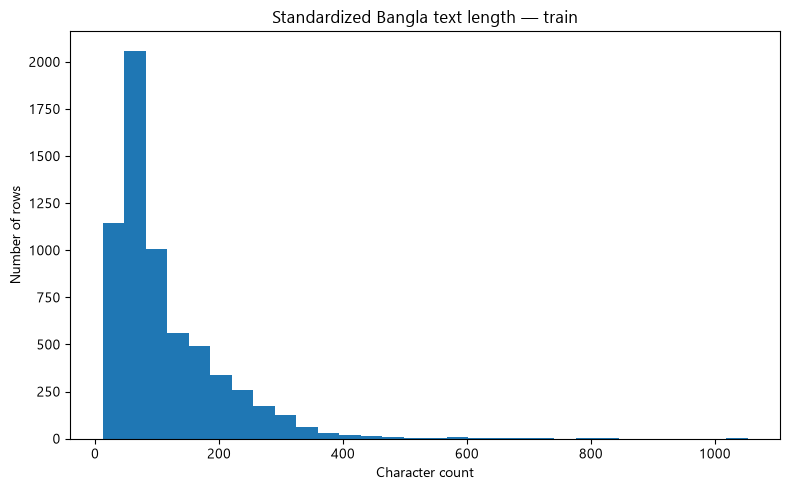

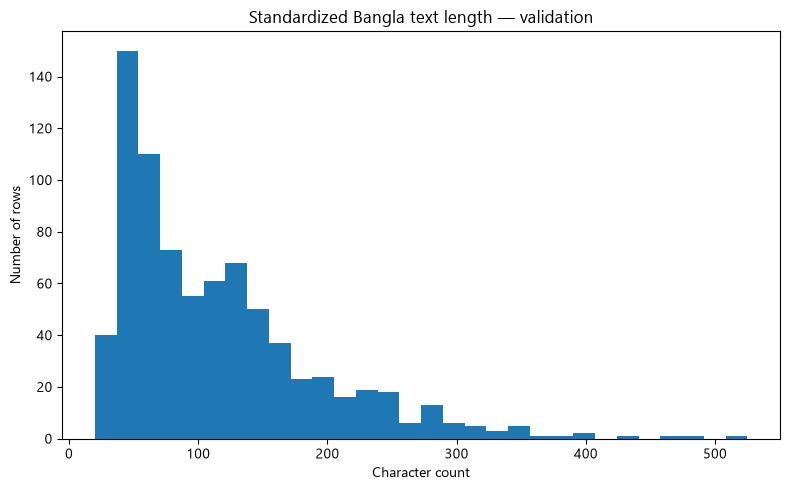

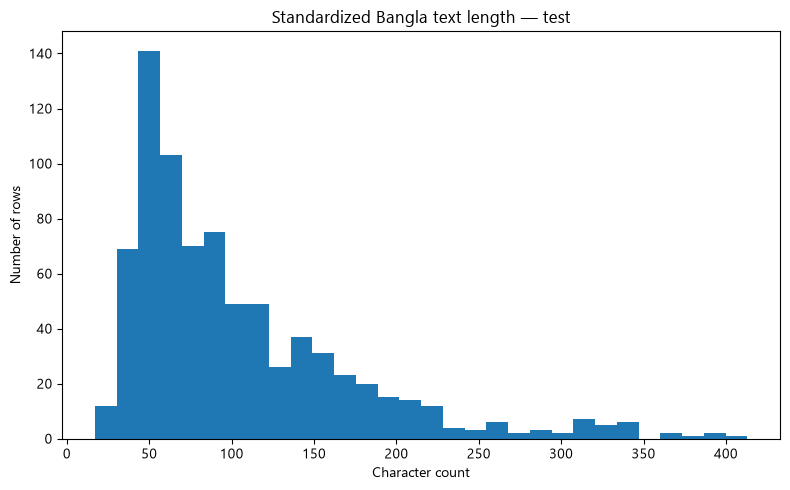

In [110]:
if TEXT_COLUMN is not None:
    for split, frame in dataframes.items():
        if "standardized_text" not in frame.columns:
            continue
        original = frame[TEXT_COLUMN]
        cleaned = frame["standardized_text"]
        lengths = cleaned.str.len()
        print(f"\n{split.upper()} TEXT QUALITY")
        print("Rows:", len(frame))
        print("Missing original text:", int(original.isna().sum()))
        print("Empty after standardization:", int(cleaned.eq("").sum()))
        print("Duplicate original text:", int(original.fillna("").astype(str).duplicated().sum()))
        print("Duplicate standardized text:", int(cleaned.duplicated().sum()))
        print("Shortest text length:", int(lengths.min()) if len(lengths) else 0)
        print("Median text length:", float(lengths.median()) if len(lengths) else 0)
        print("Longest text length:", int(lengths.max()) if len(lengths) else 0)

    for split, frame in dataframes.items():
        if "standardized_text" in frame.columns:
            plt.hist(frame["standardized_text"].str.len(), bins=30)
            plt.title(f"Standardized Bangla text length — {split}")
            plt.xlabel("Character count"); plt.ylabel("Number of rows")
            plt.tight_layout(); plt.show()
else:
    print("Set TEXT_COLUMN first.")

## Analyze the label distribution

This cell counts how many rows belong to each category in every split and plots the training counts as a bar chart. It only reports numbers and leaves the data unchanged.

The goal is to find out whether the categories are balanced. A model learns from what it sees most, so a category with far more examples than the rest can dominate training. The model may then reach a high accuracy by favoring that category while performing poorly on the smaller ones. Identifying this early helps in choosing fair evaluation metrics and deciding whether balancing is needed.

For the train, validation and test splits, the cell displays a table listing each category with its row count. Missing labels, if any, show up as a separate entry. It then draws a bar chart for the training split, where a bar much taller or shorter than the others points to an imbalance.

Roughly equal bars mean no special handling is needed. Large differences can be handled with class weights, oversampling smaller categories, or evaluating with per-class scores and macro-F1 instead of accuracy alone.


TRAIN label counts


,category,count
0,Landslides,803
1,Tropical Storm,800
2,Drought,800
3,Flood,800
4,Earthquake,800
5,Non Disaster,800
6,Human Damage,800
7,Wildfire,720



VALIDATION label counts


,category,count
0,Landslides,100
1,Tropical Storm,100
2,Drought,100
3,Flood,100
4,Earthquake,100
5,Non Disaster,100
6,Human Damage,100
7,Wildfire,90



TEST label counts


,category,count
0,Landslides,100
1,Tropical Storm,100
2,Drought,100
3,Flood,100
4,Earthquake,100
5,Non Disaster,100
6,Human Damage,100
7,Wildfire,90


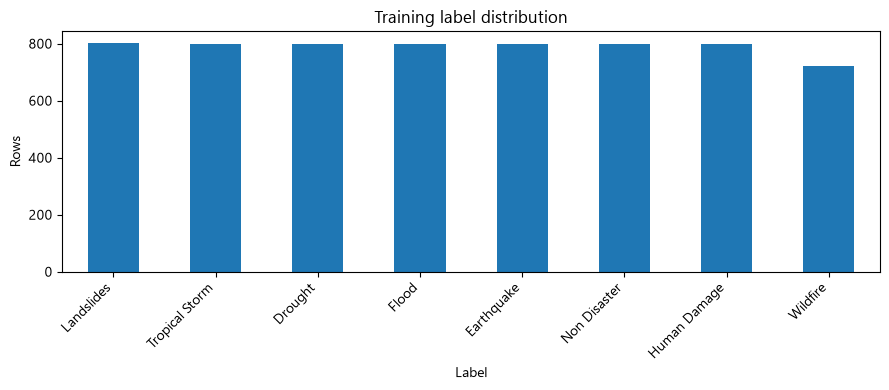

In [111]:
if LABEL_COLUMN is not None:
    for split, frame in dataframes.items():
        if LABEL_COLUMN not in frame.columns:
            print(f"{LABEL_COLUMN!r} not found in {split}.")
            continue
        print(f"\n{split.upper()} label counts")
        display(frame[LABEL_COLUMN].value_counts(dropna=False).rename_axis(LABEL_COLUMN).reset_index(name="count"))

    if "train" in dataframes and LABEL_COLUMN in dataframes["train"].columns:
        dataframes["train"][LABEL_COLUMN].value_counts(dropna=False).plot(kind="bar", figsize=(9, 4))
        plt.title("Training label distribution"); plt.xlabel("Label"); plt.ylabel("Rows")
        plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
else:
    print("No label column detected. Set LABEL_COLUMN manually if applicable.")

## Build an index of all image files

This cell scans the image folders and builds a lookup of every image file in the dataset. It prepares for the next step, where each CSV row is matched to its image. The image files themselves are not opened or changed.

For each split (train, validation and test), the cell searches the folder and its subfolders for files with valid image extensions and stores them in a sorted list called `all_image_paths`. It also builds a second lookup called `image_index`, where each image is stored under two keys: its full filename (such as `flood_12.jpg`) and its name without the extension (such as `flood_12`). Both keys are lowercase, so the match does not depend on capital letters. Each entry also remembers which split the image came from.

Building this lookup once is useful because the CSV may list an image with or without its extension, or with different capitalization. With the index ready, a name can be found quickly without searching the folders again for every row.

The cell ends by printing the total number of indexed images. For this dataset it should be 7,903, which is the sum of 6,323 train, 790 validation and 790 test images. A different number means some images are missing or the folder paths need to be checked.

In [112]:
image_index = {}
all_image_paths = {}
for split, folder in IMAGE_DIRS.items():
    paths_for_split = []
    if folder.exists():
        paths_for_split = sorted(p for p in folder.rglob("*")
                                 if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    all_image_paths[split] = paths_for_split
    for path in paths_for_split:
        image_index.setdefault(path.name.lower(), []).append((split, path))
        image_index.setdefault(path.stem.lower(), []).append((split, path))

print("Total image files indexed:", sum(len(v) for v in all_image_paths.values()))

Total image files indexed: 7903


## Match each CSV row to its image file

This cell links every CSV row to its image file on disk and stores the result in a new column called `matched_image_path`. The original CSV and image files are not changed.

For each image name, the function `find_image_path` tries a direct file path first, then searches the images of the same split, and finally searches the full index from the previous step. If nothing matches, the row is left empty. For each split, the cell prints the number of matched rows and shows up to 10 unmatched examples.

**Note: this cell can take a long time to run.** Each row is compared against every image in its split, which adds up to tens of millions of comparisons for the 6,323-row training set. Wait until all three splits print their results.

A correct match matters because a multimodal model needs the right image paired with the right text and label. For this dataset, the match rate should be 100% for all splits. This only confirms that the files exist, so a visual review of the pairs is still needed.

In [113]:
def find_image_path(value, split):
    if pd.isna(value) or not str(value).strip():
        return None

    raw = str(value).strip()
    # Support both Windows and POSIX separators, regardless of the OS running Jupyter.
    normalized = raw.replace("\\", "/")
    candidate = Path(normalized)
    candidates = [candidate]
    if not candidate.is_absolute():
        candidates.append(DATASET_PATH / candidate)

    for path in candidates:
        if path.exists() and path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            return path.resolve()

    filename = candidate.name.lower()
    stem = candidate.stem.lower()

    # Prefer a matching filename in the corresponding split.
    for path in all_image_paths.get(split, []):
        if path.name.lower() == filename or path.stem.lower() == stem:
            return path

    matches = image_index.get(filename, []) or image_index.get(stem, [])
    if matches:
        same_split = [path for match_split, path in matches if match_split == split]
        return same_split[0] if same_split else matches[0]
    return None

if IMAGE_COLUMN is not None:
    for split, frame in dataframes.items():
        if IMAGE_COLUMN not in frame.columns:
            print(f"{IMAGE_COLUMN!r} not found in {split}; skipping image matching.")
            continue
        frame["matched_image_path"] = frame[IMAGE_COLUMN].apply(lambda value: find_image_path(value, split))
        matched_count = int(frame["matched_image_path"].notna().sum())
        total = len(frame)
        print(f"{split}: matched {matched_count}/{total} rows ({matched_count / max(total, 1):.1%})")
        print("Unmatched rows:")
        display(frame.loc[frame["matched_image_path"].isna(), [IMAGE_COLUMN]].head(10))
else:
    print("Set IMAGE_COLUMN to the CSV column containing image filenames or paths.")

train: matched 6323/6323 rows (100.0%)
Unmatched rows:


,image_id


validation: matched 790/790 rows (100.0%)
Unmatched rows:


,image_id


test: matched 790/790 rows (100.0%)
Unmatched rows:


,image_id


## Review image, text and label pairs visually

This cell displays a few training examples with their image, label and Bangla text together, so the pairing can be reviewed by eye. Nothing in the data is changed.

It takes the first 6 matched rows of the training set, loads each image, converts it to RGB for display, and shows it with the label and the first 350 characters of the cleaned text as the title. If an image cannot be read, a short message appears in its place. If the matching or text cleaning sections have not been run yet, the cell prints a message asking to run them first.

A correct match in the file system does not guarantee that the image fits the text and label, so this visual review is the only way to catch mismatched pairs. The Bangla text will only display properly if a font with Bengali support is set, such as Nirmala UI on Windows.

The first rows of the dataset all belong to the same category, so these 6 examples give a limited view. Reviewing a random sample from each category gives a more reliable picture.

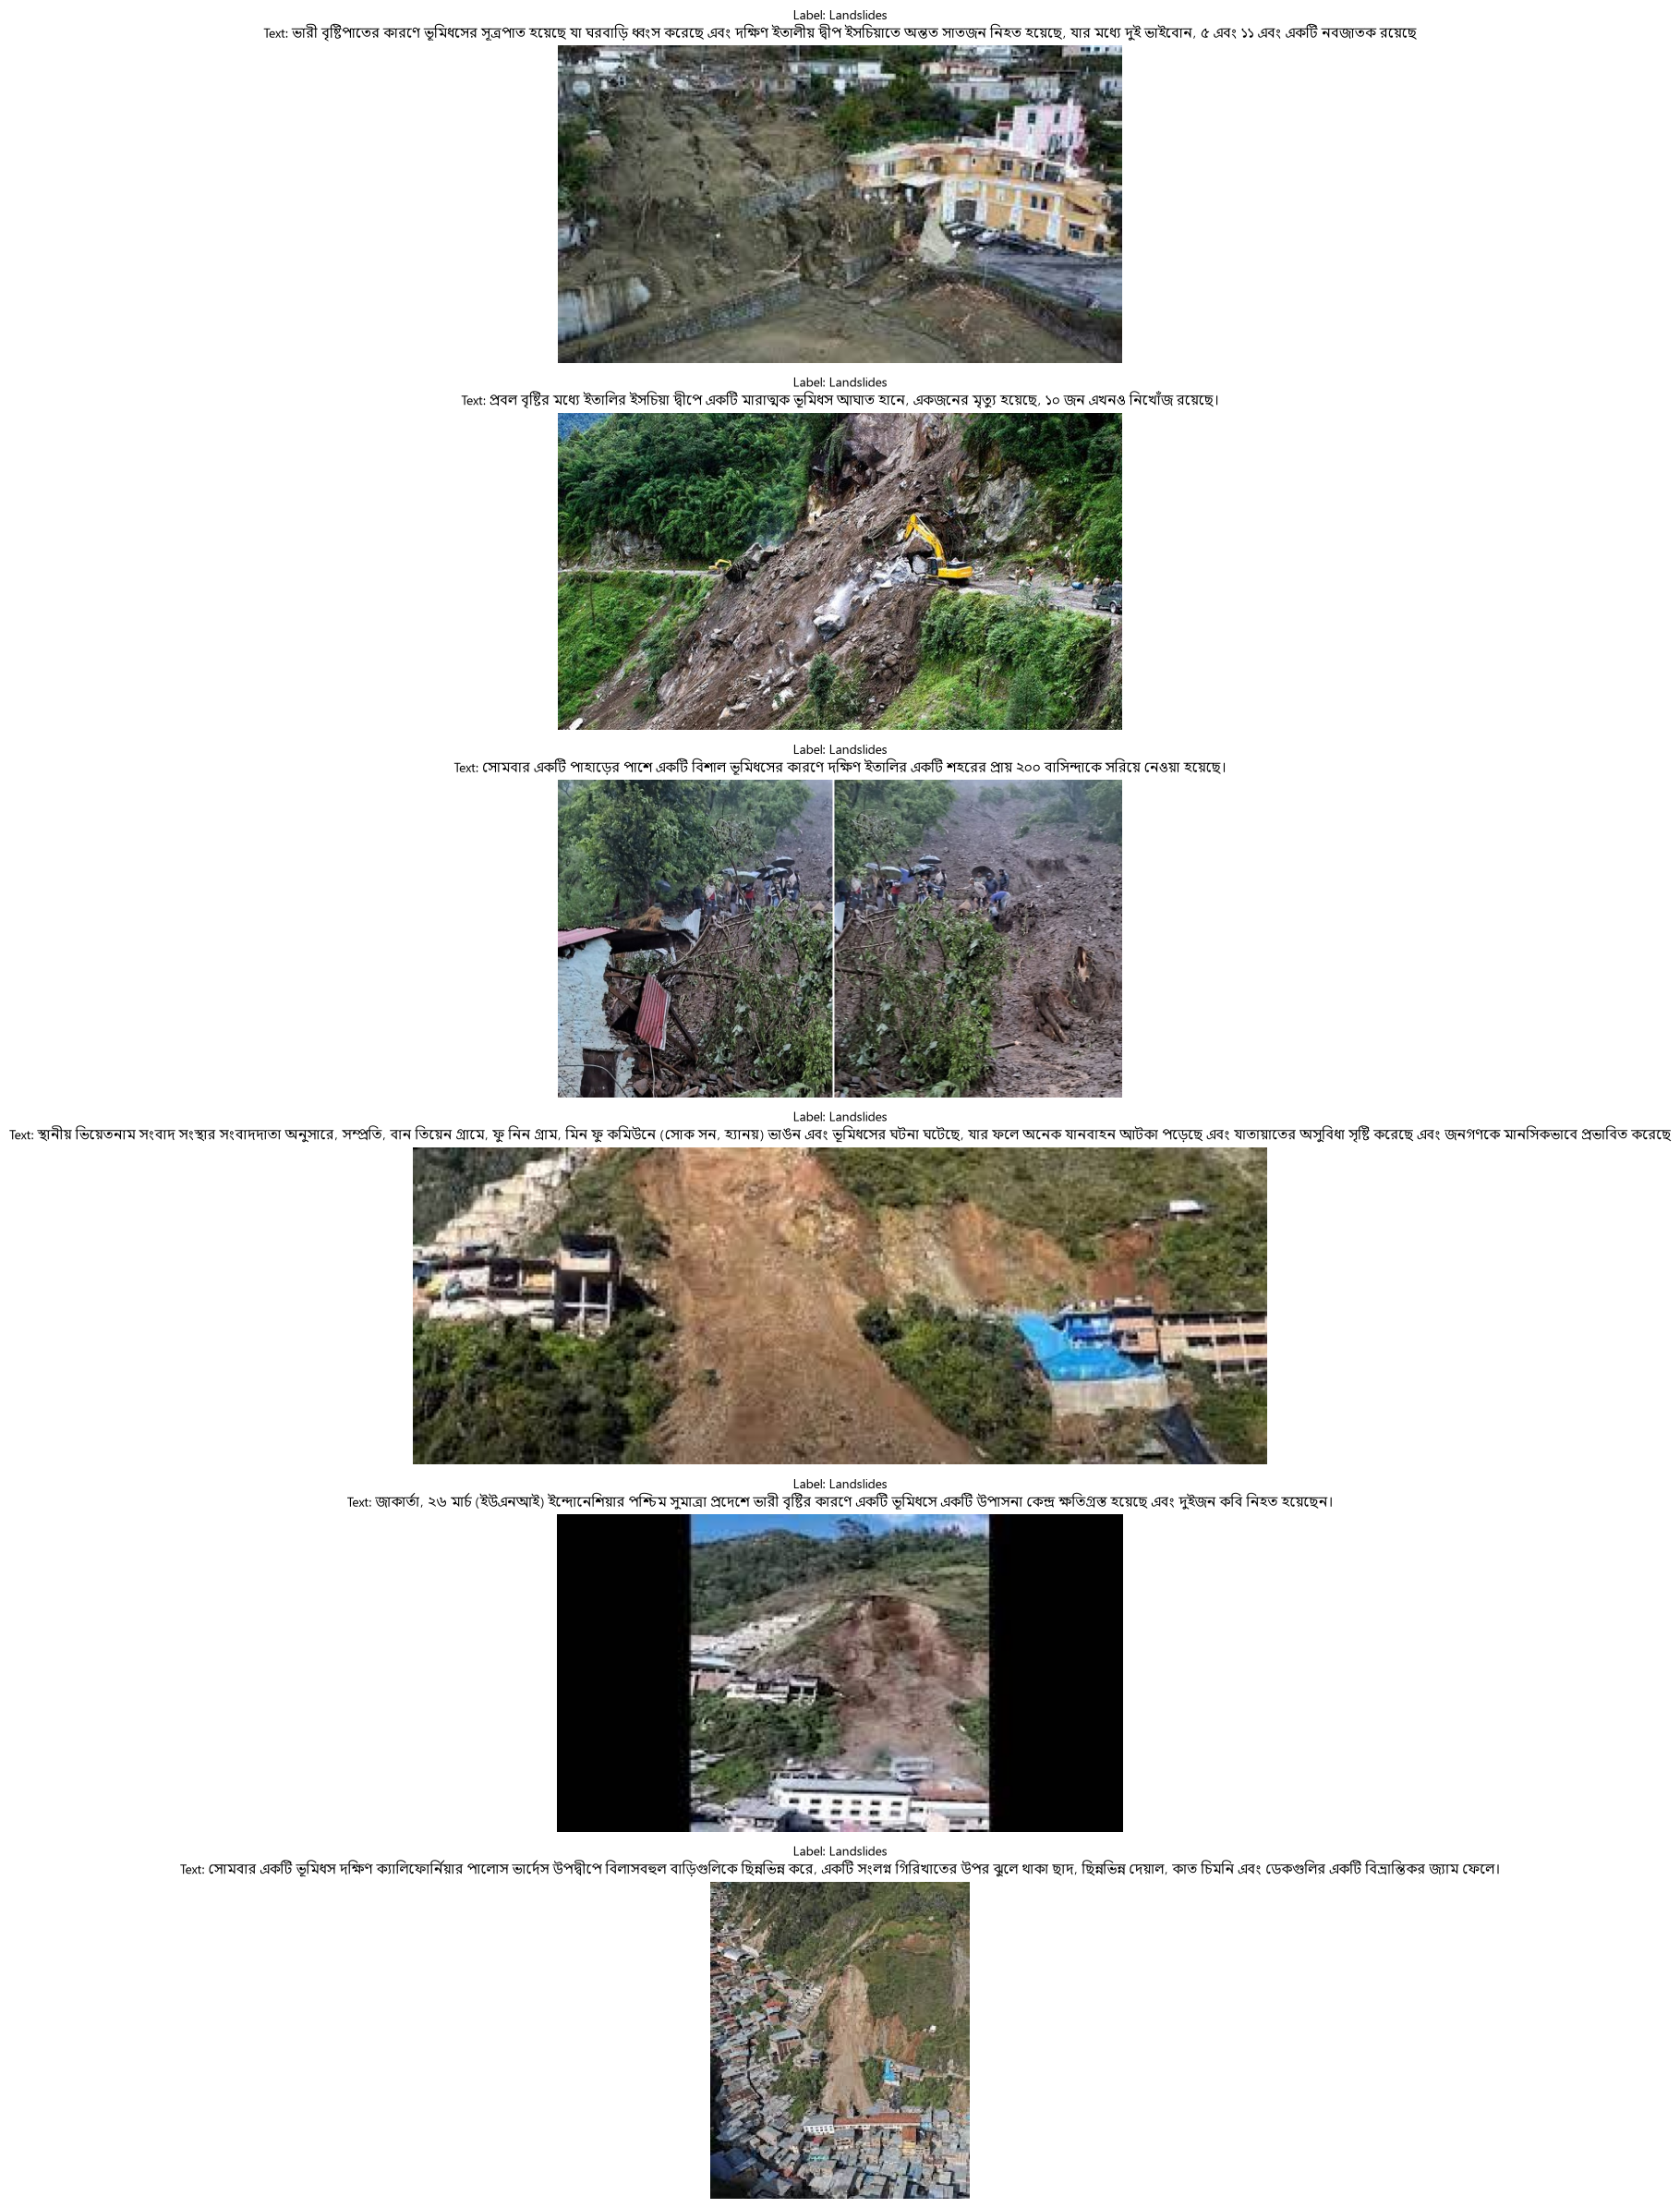

In [114]:
if "train" in dataframes and IMAGE_COLUMN is not None and TEXT_COLUMN is not None:
    frame = dataframes["train"]
    if "matched_image_path" in frame.columns and "standardized_text" in frame.columns:
        matched = frame[frame["matched_image_path"].notna()].head(6)
        if matched.empty:
            print("No matched examples to display. Check the image column and matching logic.")
        else:
            fig, axes = plt.subplots(len(matched), 1, figsize=(11, 4 * len(matched)))
            if len(matched) == 1:
                axes = [axes]
            for ax, (_, row) in zip(axes, matched.iterrows()):
                img_bgr = cv2.imread(str(row["matched_image_path"]))
                if img_bgr is None:
                    ax.set_title("Could not read image"); ax.axis("off"); continue
                ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
                text_value = str(row["standardized_text"])[:350]
                label_value = row[LABEL_COLUMN] if LABEL_COLUMN and LABEL_COLUMN in row.index else "Not configured"
                ax.set_title(f"Label: {label_value}\nText: {text_value}", fontsize=10)
                ax.axis("off")
            plt.tight_layout(); plt.show()
    else:
        print("Run the text cleaning and image matching sections first.")
else:
    print("Configure TEXT_COLUMN and IMAGE_COLUMN to display image–text pairs.")

## Find repeated image filenames across splits

This cell compares the image filenames of the train, validation and test splits and reports any names that appear in more than one split. Nothing in the data is changed.

For each split, it builds a set of lowercase filenames. It then compares every pair of splits (train and validation, train and test, validation and test) and prints how many filenames they share, along with up to 10 examples if any are found.

This matters because the same image appearing in both training and test data lets a model see the answer during training, which makes the test results look better than they really are. This problem is called data leakage.

This is only a filename-level warning. Two different images can share a name, and the same image can have different names, so a result of zero does not prove the splits are free of duplicates. If the filenames are unique by design, as in this dataset where the numbering continues across splits, a zero result is expected. Comparing file hashes is a more reliable way to detect identical images.

In [115]:
split_file_names = {
    split: {p.name.lower() for p in paths}
    for split, paths in all_image_paths.items()
}
split_names = list(split_file_names)
for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        a, b = split_names[i], split_names[j]
        overlap = split_file_names[a] & split_file_names[b]
        print(f"Shared filenames between {a} and {b}: {len(overlap)}")
        if overlap:
            print("Examples:", sorted(overlap)[:10])

Shared filenames between train and validation: 0
Shared filenames between train and test: 0
Shared filenames between validation and test: 0


## Save the quality-checked CSV files

This cell saves the updated tables as new CSV files so the cleaned text and image paths can be reused without repeating the earlier steps. The original CSV files and images are not overwritten.

It creates a folder called `quality_alignment_output` inside the dataset folder if it does not already exist. Then it writes one file for each split, named `Disaster_train_quality_checked.csv`, `Disaster_validation_quality_checked.csv` and `Disaster_test_quality_checked.csv`. Each file contains the original columns plus the new `standardized_text` and `matched_image_path` columns. The files are saved with UTF-8 with BOM encoding (`utf-8-sig`), so Bangla text displays correctly when opened in Excel. If the dataset folder does not exist, nothing is saved and a message is printed.

The `matched_image_path` column holds full paths from this computer, which will not work on another machine. It should be removed or converted to relative paths before the files are shared.

In [116]:
OUTPUT_PATH = DATASET_PATH / "quality_alignment_output"
if DATASET_PATH.exists():
    OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
    for split, frame in dataframes.items():
        output_csv = OUTPUT_PATH / f"Disaster_{split}_quality_checked.csv"
        frame.to_csv(output_csv, index=False, encoding="utf-8-sig")
        print("Saved:", output_csv)
else:
    print("Output not saved because DATASET_PATH does not exist. Fix the path in Section 1.")

Saved: D:\STUDY MATERIALS\7th semester\CSE-4878 Machine Learning and Data Mining Lab\BanglaCalamityMMD\quality_alignment_output\Disaster_train_quality_checked.csv
Saved: D:\STUDY MATERIALS\7th semester\CSE-4878 Machine Learning and Data Mining Lab\BanglaCalamityMMD\quality_alignment_output\Disaster_validation_quality_checked.csv
Saved: D:\STUDY MATERIALS\7th semester\CSE-4878 Machine Learning and Data Mining Lab\BanglaCalamityMMD\quality_alignment_output\Disaster_test_quality_checked.csv


### save a resized copy of the sample image

This saves one `224 × 224` example in a new folder. It does not alter the original image. For actual model training, create a reproducible preprocessing pipeline and apply it consistently to all splits.

In [117]:
if image_rgb is not None and DATASET_PATH.exists():
    output_folder = DATASET_PATH / "preprocessed_examples"
    output_folder.mkdir(parents=True, exist_ok=True)
    output_path = output_folder / f"{image_path.stem}_resized.jpg"
    success = cv2.imwrite(str(output_path), cv2.cvtColor(resized_image, cv2.COLOR_RGB2BGR))
    print("Saved resized copy:" if success else "Could not save image:", output_path)
else:
    print("No sample image or valid dataset folder; skipped saving.")

Saved resized copy: D:\STUDY MATERIALS\7th semester\CSE-4878 Machine Learning and Data Mining Lab\BanglaCalamityMMD\preprocessed_examples\drought_1_resized.jpg


## Conclusion

This project worked with BanglaCalamityMMD, a multimodal dataset that pairs disaster images with Bangla text across eight categories: Drought, Earthquake, Flood, Human Damage, Landslides, Non Disaster, Tropical Storm and Wildfire. The goal is to identify the type of disaster from an image and its Bangla description.

The work so far covered the data preparation stage. The train, validation and test splits (6,323, 790 and 790 samples) were loaded and inspected, and basic image-processing operations were explored to understand how images are represented and which transformations are safe for disaster images. The Bangla text was normalized conservatively and checked for missing values, duplicates and length. The label distribution was found to be nearly balanced, and every text record was matched to its image. The matched pairs were reviewed visually, and the quality-checked files were saved without changing the original data.

The main findings are that the dataset is well organized, complete and balanced, and that it is suitable for training image-only, text-only and combined models. 

The next steps are to train baseline models on each modality separately (a pretrained image model such as ResNet or ViT, and a Bangla text model such as BanglaBERT), and then combine them in a multimodal model.